# 01 — Exploratory Data Analysis (Kaggle crop yield, training split only)

**Framing.** Phase 1 concluded the Kaggle data is **likely synthetic** (uniform
feature distributions, near-zero correlation between features that should be
related, crop type with no effect on yield). This notebook therefore treats it
as a *controlled benchmark*: we are learning how the data-generating process
behaves, not agronomy. Real-world conclusions come from the India data (notebook 04).

Only the **training split** (80 %) is used here. The test split stays locked
until the final evaluation.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))  # make `src` importable when run from notebooks/

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf
from statsmodels.nonparametric.smoothers_lowess import lowess

from src import config
from src.data import load_split
from src.eda import binned_means, feature_signal, top_pearson_feature
from src.plots import axis_label, save_figure

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid")
train, _ = load_split()  # the test split is deliberately discarded here
y = train[config.TARGET]
Y_LABEL = axis_label(config.TARGET)

## 1. Dataset overview

In [2]:
print("Shape:", train.shape)
overview = pd.DataFrame(
    {"dtype": train.dtypes.astype(str), "missing": train.isna().sum(), "n_unique": train.nunique()}
)
overview

Shape: (3840, 15)


,dtype,missing,n_unique
soil_ph,float64,0,3840
soil_moisture,float64,0,3840
avg_temperature,float64,0,3840
total_rainfall,float64,0,3840
fertilizer_amount,float64,0,3840
pesticide_usage,float64,0,3840
sunlight_hours,float64,0,3840
nitrogen_content,float64,0,3840
phosphorus_content,float64,0,3840
potassium_content,float64,0,3840


In [3]:
train.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
soil_ph,3840.0,6.488,1.155,4.500,5.489,6.501,7.462,8.499
soil_moisture,3840.0,29.670,11.555,10.006,19.627,29.370,39.718,49.987
avg_temperature,3840.0,22.548,7.203,10.006,16.300,22.645,28.864,34.986
total_rainfall,3840.0,662.759,317.139,100.053,392.748,661.918,935.150,1199.891
fertilizer_amount,3840.0,174.138,71.259,50.049,114.161,174.675,234.580,299.933
pesticide_usage,3840.0,7.520,4.318,0.001,3.723,7.582,11.213,14.997
sunlight_hours,3840.0,2001.868,579.353,1001.381,1503.577,2004.362,2509.893,2998.537
nitrogen_content,3840.0,1.750,0.726,0.500,1.111,1.759,2.382,3.000
phosphorus_content,3840.0,0.850,0.375,0.200,0.524,0.856,1.169,1.500
potassium_content,3840.0,1.256,0.430,0.500,0.893,1.267,1.628,1.999


**Interpretation.** 3,840 training rows, 11 numeric features, 3 categorical
features and the target. There are **no missing values**, so no imputation step
is needed in the preprocessing pipeline. Every numeric feature sits inside a
neat, round range (pH 4.5–8.5, rainfall 100–1,200 mm, sunlight 1,000–3,000 h),
consistent with values drawn from a uniform generator.

## 2. Target distribution — should the target be log-transformed?

skewness raw = -0.098, log1p = -0.517


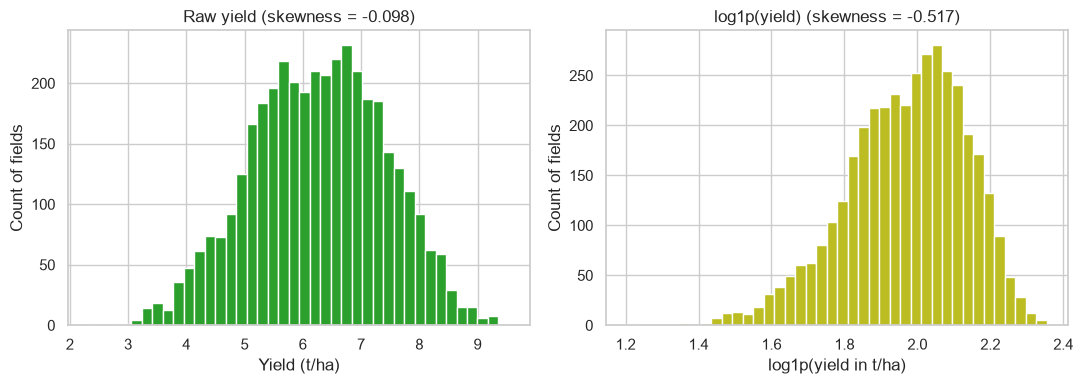

In [4]:
skew_raw, skew_log = y.skew(), np.log1p(y).skew()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(y, bins=40, color="tab:green", edgecolor="white")
axes[0].set(title=f"Raw yield (skewness = {skew_raw:.3f})", xlabel=Y_LABEL, ylabel="Count of fields")
axes[1].hist(np.log1p(y), bins=40, color="tab:olive", edgecolor="white")
axes[1].set(title=f"log1p(yield) (skewness = {skew_log:.3f})", xlabel="log1p(yield in t/ha)", ylabel="Count of fields")
save_figure(fig, "eda_target_distribution")
print(f"skewness raw = {skew_raw:.3f}, log1p = {skew_log:.3f}")

**Interpretation.** Raw yield is almost perfectly symmetric (skewness ≈ −0.10),
well below the |skew| > 1 threshold. log1p would make it *more* skewed (≈ −0.52,
a long left tail). **Decision: model the raw target in t/ha, no log transform.**
A convenient side effect: every metric is naturally in t/ha.

## 3. Numeric feature distributions (soil / weather / farming)

Excess kurtosis (uniform = -1.2, normal = 0):
soil_ph                -1.19
soil_moisture          -1.21
nitrogen_content       -1.23
phosphorus_content     -1.20
potassium_content      -1.18
avg_temperature        -1.19
total_rainfall         -1.19
sunlight_hours         -1.20
fertilizer_amount      -1.17
pesticide_usage        -1.20
irrigation_frequency   -1.26


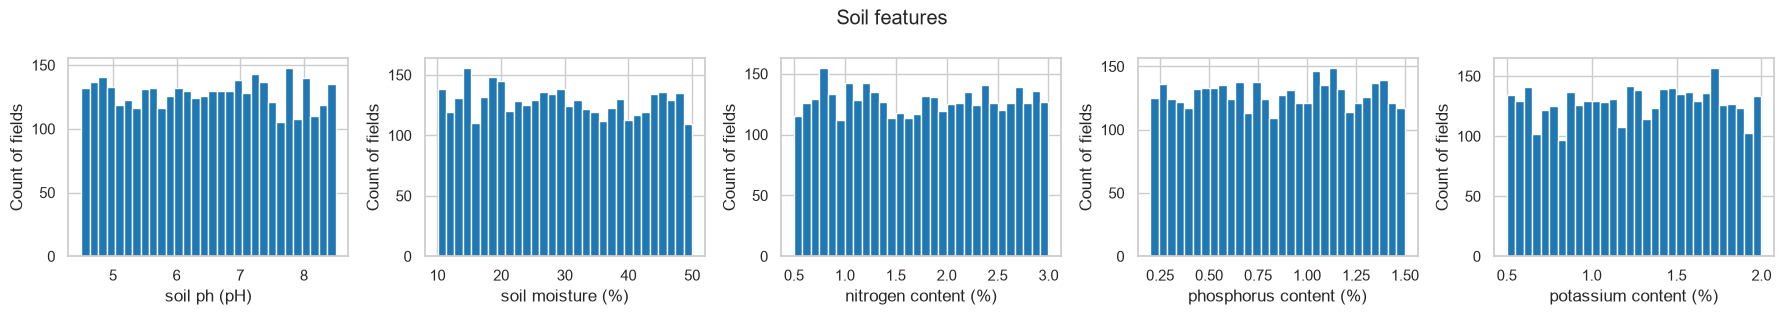

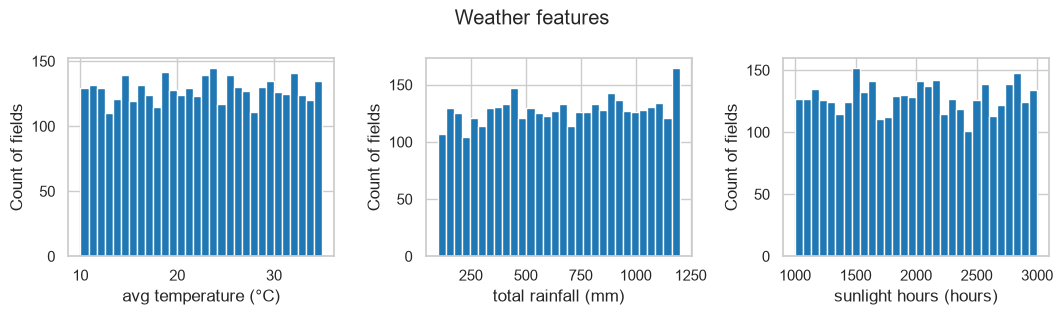

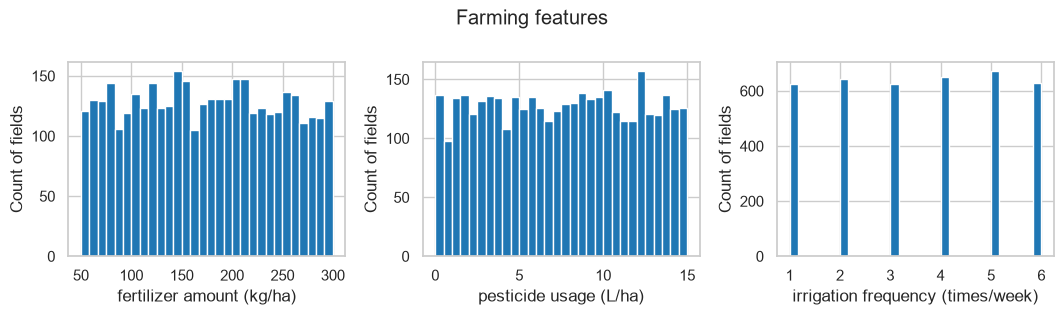

In [5]:
for group_name, cols in [
    ("soil", config.SOIL_FEATURES),
    ("weather", config.WEATHER_FEATURES),
    ("farming", config.FARMING_FEATURES),
]:
    fig, axes = plt.subplots(1, len(cols), figsize=(3.6 * len(cols), 3.2))
    for ax, col in zip(axes, cols):
        ax.hist(train[col], bins=30, color="tab:blue", edgecolor="white")
        ax.set(xlabel=axis_label(col), ylabel="Count of fields")
    fig.suptitle(f"{group_name.capitalize()} features")
    save_figure(fig, f"eda_hist_{group_name}")

print("Excess kurtosis (uniform = -1.2, normal = 0):")
print(train[config.NUMERIC_FEATURES].kurt().round(2).to_string())

**Interpretation.** Every numeric histogram is flat — a rectangle, not a bell
curve — and every excess kurtosis is ≈ −1.2, the theoretical value for a uniform
distribution. Real soil and weather variables are almost never uniform (rainfall
is typically right-skewed). This is the strongest single piece of evidence that
the data is synthetic. Because the features are bounded and roughly uniform,
standard scaling is safe (no extreme values to dominate the mean/std).

## 4. Categorical features

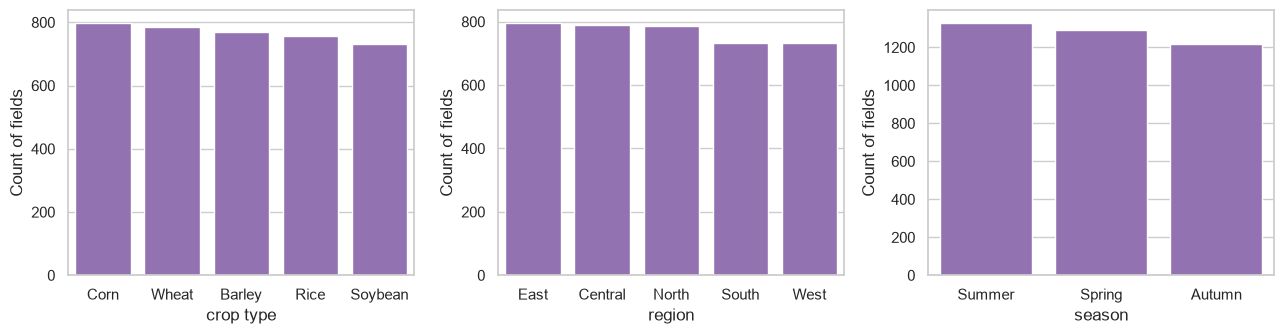

In [6]:
fig, axes = plt.subplots(1, len(config.CATEGORICAL_FEATURES), figsize=(13, 3.5))
for ax, col in zip(axes, config.CATEGORICAL_FEATURES):
    order = train[col].value_counts().index
    sns.countplot(data=train, x=col, order=order, ax=ax, color="tab:purple")
    ax.set(xlabel=axis_label(col), ylabel="Count of fields")
save_figure(fig, "eda_counts_categorical")

**Interpretation.** Each category level appears with almost equal frequency
(5 crops, 5 regions, 3 seasons, each close to 1/k of rows). No rare levels, so
one-hot encoding will not create near-empty columns, and a random split keeps
every level in both train and test.

## 5. Yield by crop, region and season

crop_type: group means {'Barley': 6.31, 'Corn': 6.25, 'Rice': 6.24, 'Soybean': 6.27, 'Wheat': 6.24}  one-way ANOVA p = 0.705
region: group means {'Central': 6.26, 'East': 6.31, 'North': 6.31, 'South': 6.2, 'West': 6.23}  one-way ANOVA p = 0.242
season: group means {'Autumn': 6.23, 'Spring': 6.27, 'Summer': 6.28}  one-way ANOVA p = 0.531


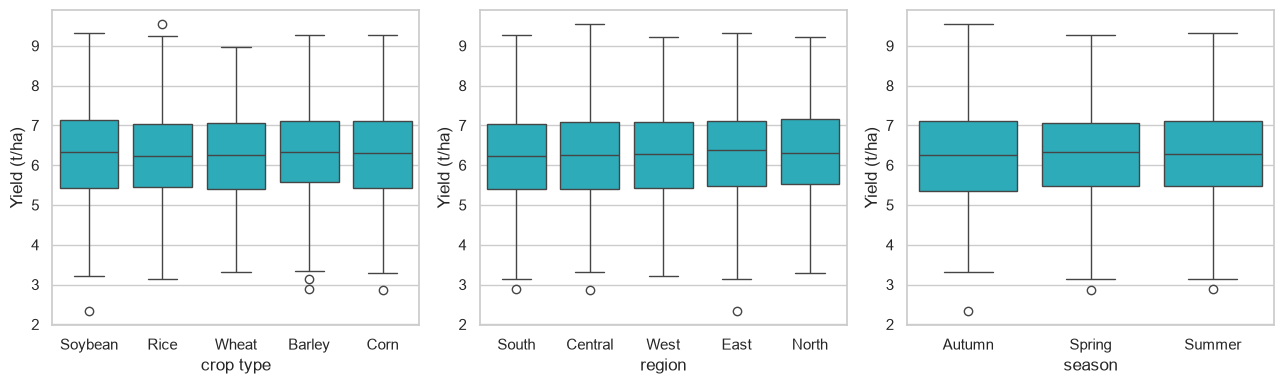

In [7]:
fig, axes = plt.subplots(1, len(config.CATEGORICAL_FEATURES), figsize=(13, 4))
for ax, col in zip(axes, config.CATEGORICAL_FEATURES):
    sns.boxplot(data=train, x=col, y=config.TARGET, ax=ax, color="tab:cyan")
    ax.set(xlabel=axis_label(col), ylabel=Y_LABEL)
save_figure(fig, "eda_yield_by_context")

for col in config.CATEGORICAL_FEATURES:
    means = train.groupby(col)[config.TARGET].mean()
    anova_p = smf.ols(f"{config.TARGET} ~ C({col})", data=train).fit().f_pvalue
    print(f"{col}: group means {means.round(2).to_dict()}  one-way ANOVA p = {anova_p:.3f}")

**Interpretation.** Median yield is essentially identical across all five crops,
all five regions and all three seasons, and the one-way ANOVA p-values printed
above are all far above 0.05. In reality corn yields roughly 3× soybean per
hectare, so a flat crop effect is a clear sign of synthetic generation. For
modelling it means the context variables should contribute almost nothing.

## 6. Correlation heatmaps — Pearson and Spearman

Largest |Spearman - Pearson| gap: 0.013


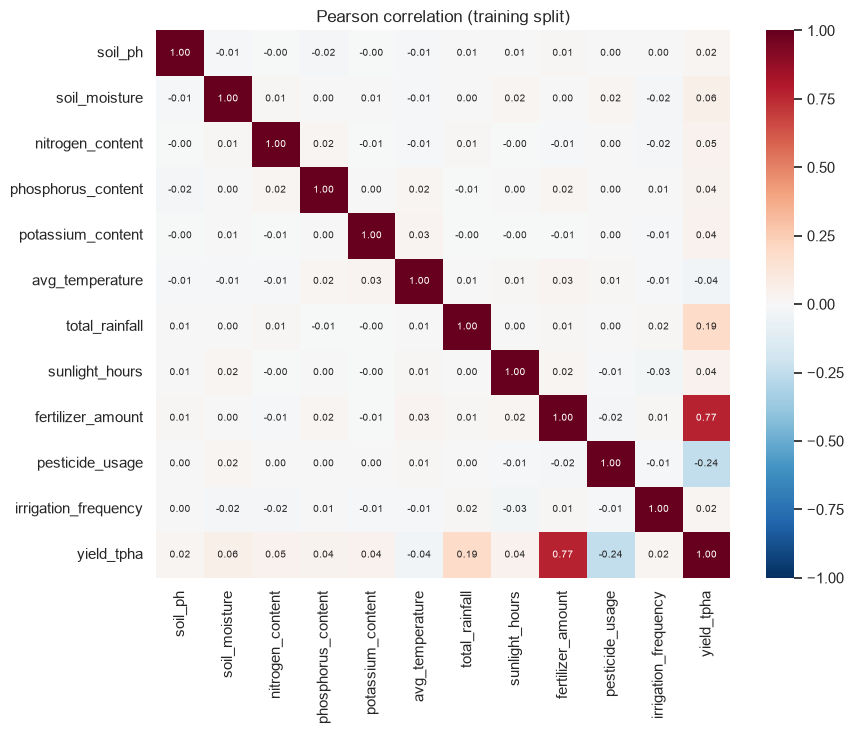

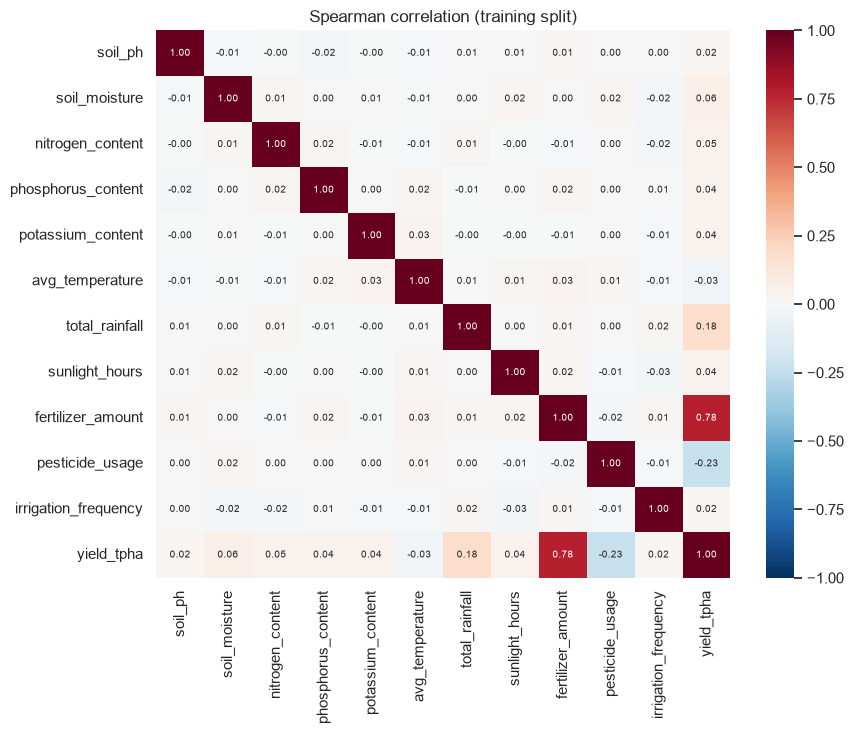

In [8]:
num_cols = config.NUMERIC_FEATURES + [config.TARGET]
pearson = train[num_cols].corr(method="pearson")
spearman = train[num_cols].corr(method="spearman")
for name, mat in [("pearson", pearson), ("spearman", spearman)]:
    fig, ax = plt.subplots(figsize=(9, 7.5))
    sns.heatmap(mat, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax, annot_kws={"size": 7})
    ax.set_title(f"{name.capitalize()} correlation (training split)")
    save_figure(fig, f"eda_corr_{name}")

diff = (spearman - pearson).abs()
print("Largest |Spearman - Pearson| gap:", round(diff.to_numpy().max(), 3))

**Interpretation.** The two heatmaps are practically identical: the largest gap
between Spearman and Pearson is tiny (printed above). Spearman captures any
*monotonic* relationship, Pearson only a *linear* one, so a big gap would signal
monotonic curvature. No gap means no strong monotonic curvature — **but** both
measures are blind to *non-monotonic* shapes such as an optimum (a pH sweet
spot). Section 10 tests for those directly. Off-diagonal feature–feature
correlations are all ≈ 0: the features were generated independently.

## 7. Yield vs the 5 strongest features, with LOWESS trend

Top 5 by |Pearson r|: ['fertilizer_amount', 'pesticide_usage', 'total_rainfall', 'soil_moisture', 'nitrogen_content']


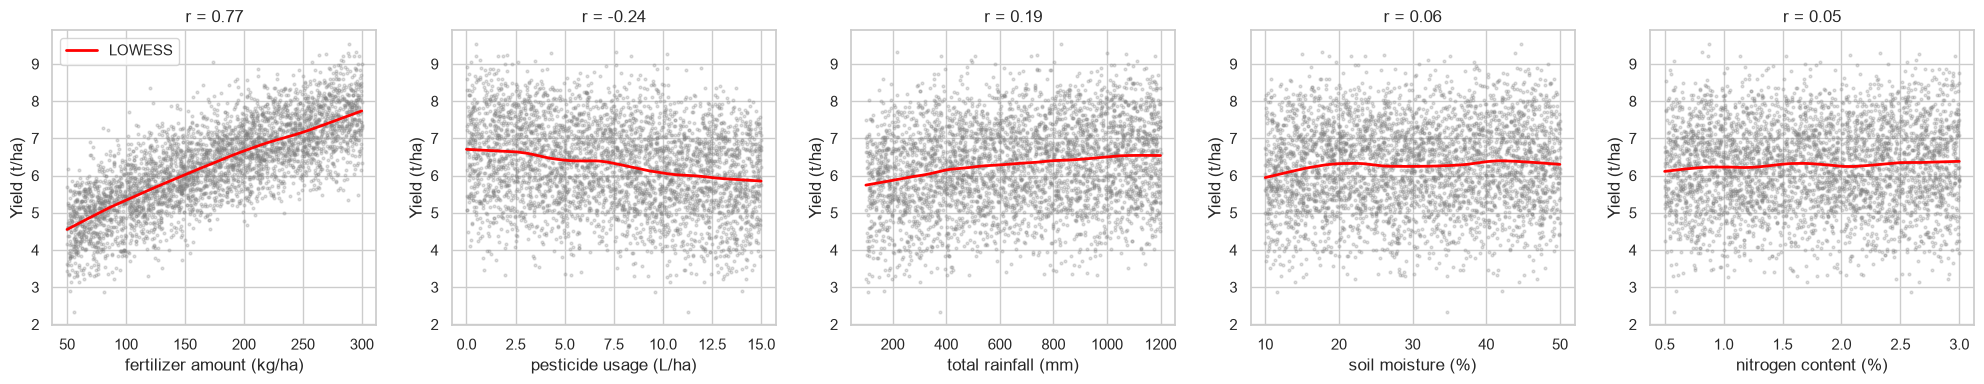

In [9]:
LOWESS_FRAC = 0.3  # fraction of points in each local fit: smooth but able to bend
top5 = pearson[config.TARGET].drop(config.TARGET).abs().sort_values(ascending=False).index[:5]
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, col in zip(axes, top5):
    ax.scatter(train[col], y, s=4, alpha=0.25, color="grey")
    trend = lowess(y, train[col], frac=LOWESS_FRAC)
    ax.plot(trend[:, 0], trend[:, 1], color="red", lw=2, label="LOWESS")
    ax.set(xlabel=axis_label(col), ylabel=Y_LABEL, title=f"r = {pearson.loc[col, config.TARGET]:.2f}")
axes[0].legend()
save_figure(fig, "eda_scatter_top5_lowess")
print("Top 5 by |Pearson r|:", list(top5))

**Interpretation.** Fertilizer dominates: a strong, tight upward trend
(r ≈ 0.77) whose LOWESS line bends slightly — steeper at low doses and flatter
at high doses (diminishing returns). Pesticide has a moderate negative trend and
rainfall a weak positive one that levels off at high rainfall. Soil moisture and
nitrogen show clouds with an almost flat trend. The scatter is wide at every x
value, so no single feature comes close to predicting yield on its own apart
from fertilizer.

## 8. Outliers (IQR rule) — reported, not removed

In [10]:
IQR_MULTIPLIER = 1.5  # Tukey's standard fence
q1, q3 = train[num_cols].quantile(0.25), train[num_cols].quantile(0.75)
iqr = q3 - q1
lower, upper = q1 - IQR_MULTIPLIER * iqr, q3 + IQR_MULTIPLIER * iqr
outliers = ((train[num_cols] < lower) | (train[num_cols] > upper)).sum()
pd.DataFrame({"lower_fence": lower, "upper_fence": upper, "n_outliers": outliers}).round(2)

,lower_fence,upper_fence,n_outliers
soil_ph,2.53,10.42,0
soil_moisture,-10.51,69.85,0
nitrogen_content,-0.80,4.29,0
phosphorus_content,-0.44,2.14,0
potassium_content,-0.21,2.73,0
avg_temperature,-2.55,47.71,0
total_rainfall,-420.86,1748.75,0
sunlight_hours,-5.90,4019.37,0
fertilizer_amount,-66.47,415.21,0
pesticide_usage,-7.51,22.45,0


**Interpretation.** No numeric feature has a single IQR outlier. That is exactly
what a uniform distribution produces: its whole range spans only 2 × IQR, so the
1.5 × IQR fences lie outside the data. Only the target has a handful of
outliers (listed above), a small share of rows that are plausible yields, so
nothing is removed.

## 9. Multicollinearity early warning: feature pairs with |r| > 0.7

In [11]:
HIGH_CORR = 0.7
feat_corr = train[config.NUMERIC_FEATURES].corr().abs()
upper_tri = feat_corr.where(np.triu(np.ones(feat_corr.shape, dtype=bool), k=1))
pairs = upper_tri.stack()
print("Pairs above |0.7|:", pairs[pairs > HIGH_CORR].to_dict())
print("Largest feature-feature |r|:", round(pairs.max(), 3))

Pairs above |0.7|: {}
Largest feature-feature |r|: 0.027


**Interpretation.** No pair of numeric features exceeds |r| = 0.7 — the largest
is below 0.03. Multicollinearity will not be a problem, so linear coefficients
can be interpreted individually (confirmed formally with VIF in notebook 02).

## 10. Non-linearity check: Pearson, Spearman, mutual information and binned means

A near-zero Pearson r does **not** mean "no effect": an inverted-U (an optimum)
has r ≈ 0 but a real effect. For every numeric feature we compute:

* **Pearson r** (linear) and **Spearman ρ** (monotonic)
* **Mutual information (MI)** — detects any dependence. `mi_linear` is the MI a
  purely linear relationship with the same r would have; MI far above it suggests
  non-linearity. `mi_noise_floor` is MI against a shuffled target (pure noise).
* **η² vs r²** — the correlation ratio from 10 quantile bins vs the variance a
  straight line explains, with an F-test (`p_nonlinear`, 8 df, general shape).
* **Quadratic test** — p-value of x² in yield ~ x + x² (`p_quadratic`, 1 df, sensitive to optima and U-shapes).

With 11 features tested, a Bonferroni threshold of 0.05 / 11 ≈ 0.0045 is used
to avoid calling chance wiggles "curvature".

In [12]:
BONFERRONI_ALPHA = 0.05 / len(config.NUMERIC_FEATURES)
signal = feature_signal(train)
config.TABLES_DIR.mkdir(parents=True, exist_ok=True)
signal.to_csv(config.TABLES_DIR / "feature_signal.csv")
signal.round(4)

,pearson_r,spearman_rho,mutual_info,mi_linear,mi_noise_floor,r_squared,eta_squared,p_nonlinear,p_quadratic
feature,,,,,,,,,
fertilizer_amount,0.7696,0.7787,0.4533,0.4487,0.0083,0.5924,0.5895,1.0000,0.0000
pesticide_usage,-0.2436,-0.2307,0.0261,0.0306,0.0020,0.0593,0.0626,0.0995,0.8160
total_rainfall,0.1929,0.1824,0.0246,0.0190,0.0000,0.0372,0.0418,0.0200,0.0015
soil_moisture,0.0603,0.0565,0.0044,0.0018,0.0068,0.0036,0.0070,0.1159,0.2489
nitrogen_content,0.0460,0.0452,0.0000,0.0011,0.0000,0.0021,0.0042,0.4433,0.8414
sunlight_hours,0.0441,0.0423,0.0000,0.0010,0.0000,0.0019,0.0058,0.0585,0.0635
potassium_content,0.0425,0.0420,0.0000,0.0009,0.0015,0.0018,0.0024,0.9740,0.5498
phosphorus_content,0.0375,0.0362,0.0007,0.0007,0.0018,0.0014,0.0059,0.0284,0.0030
avg_temperature,-0.0362,-0.0319,0.0000,0.0007,0.0107,0.0013,0.0048,0.0991,0.7048


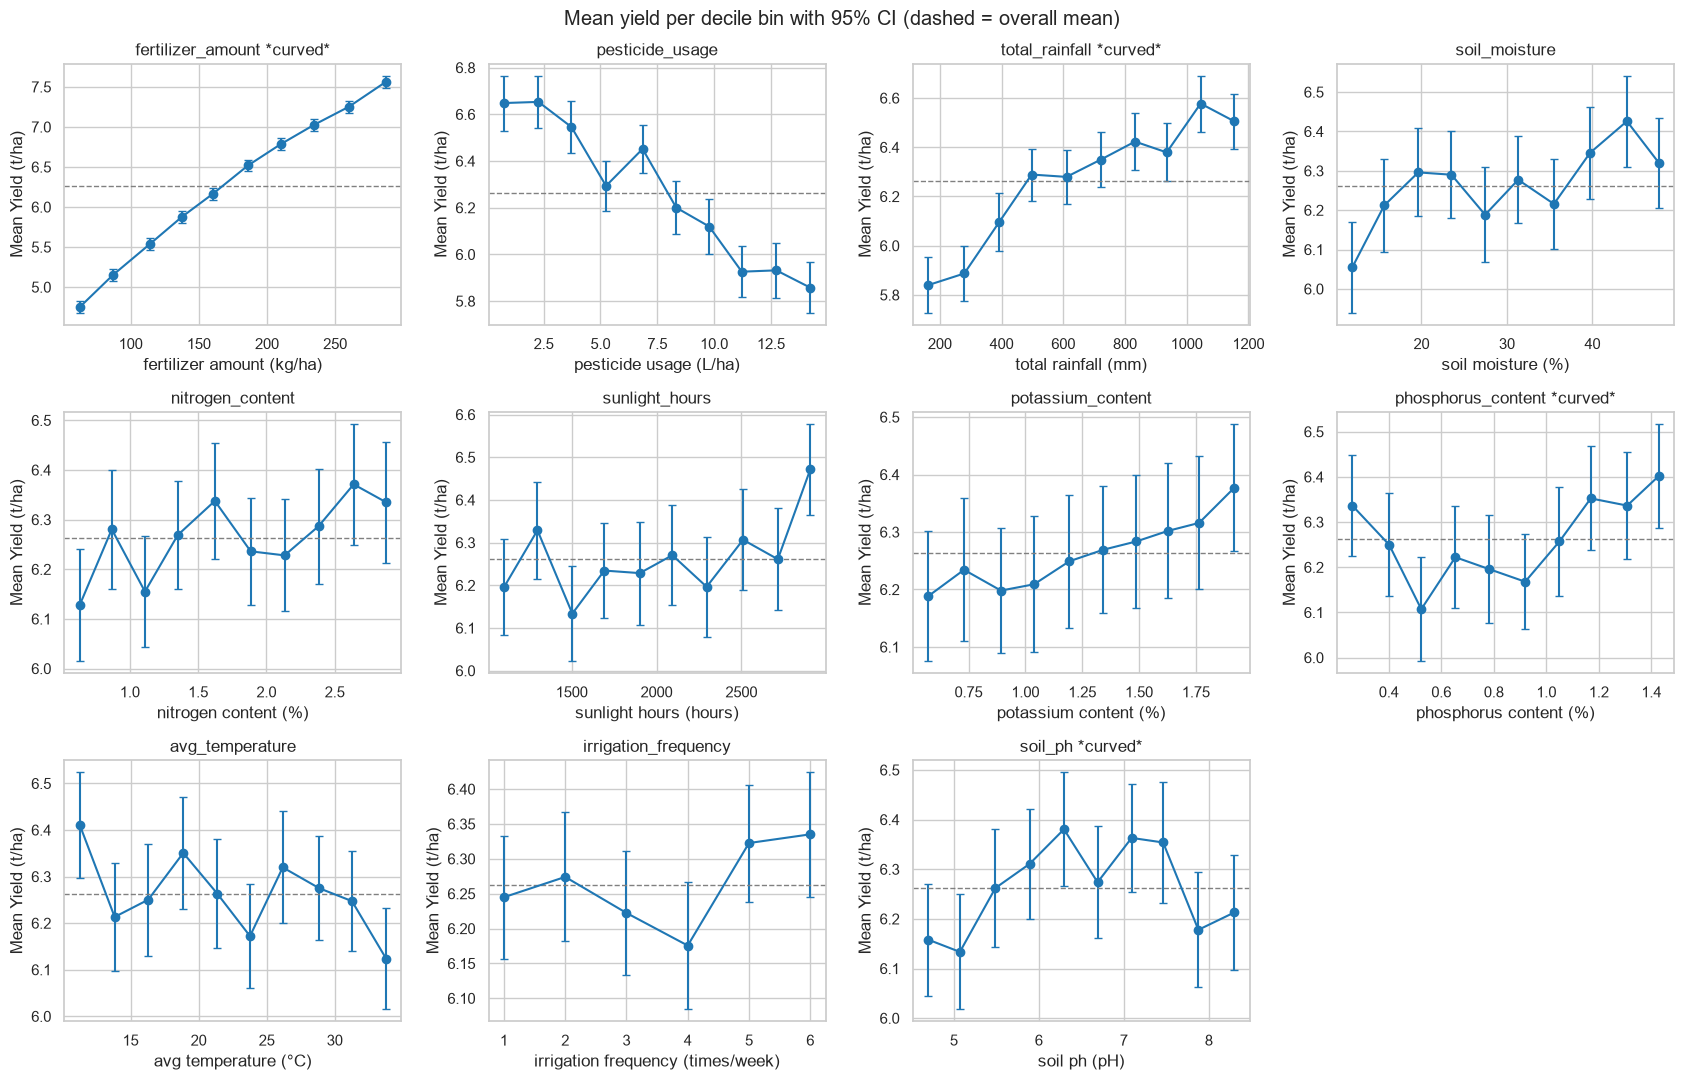

In [13]:
fig, axes = plt.subplots(3, 4, figsize=(17, 11))
for ax, col in zip(axes.flat, signal.index):
    b = binned_means(train[col], y)
    ax.errorbar(
        b["x_mid"], b["mean"], yerr=[b["mean"] - b["ci_low"], b["ci_high"] - b["mean"]],
        fmt="o-", capsize=3, color="tab:blue",
    )
    ax.axhline(y.mean(), color="grey", ls="--", lw=1)
    flag = " *curved*" if signal.loc[col, "p_quadratic"] < BONFERRONI_ALPHA else ""
    ax.set(xlabel=axis_label(col), ylabel="Mean " + Y_LABEL, title=f"{col}{flag}")
axes.flat[-1].axis("off")
fig.suptitle("Mean yield per decile bin with 95% CI (dashed = overall mean)")
save_figure(fig, "eda_binned_means")

In [14]:
curved = signal[signal["p_quadratic"] < BONFERRONI_ALPHA]
print(f"Features with significant curvature (p_quadratic < {BONFERRONI_ALPHA:.4f}):")
for col in curved.index:
    fit = smf.ols(f"{config.TARGET} ~ {col} + I({col}**2)", data=train).fit()
    vertex = -fit.params[col] / (2 * fit.params[f"I({col} ** 2)"])
    lo, hi = train[col].min(), train[col].max()
    where = f"vertex at {vertex:.2f} (inside range)" if lo < vertex < hi else "vertex outside range (monotone bend)"
    shape = "concave (∩)" if fit.params[f"I({col} ** 2)"] < 0 else "convex (∪)"
    print(f"  {col:20s} r={signal.loc[col, 'pearson_r']:+.3f}  p_quad={signal.loc[col, 'p_quadratic']:.1e}  {shape}, {where}")

Features with significant curvature (p_quadratic < 0.0045):
  fertilizer_amount    r=+0.770  p_quad=1.8e-10  concave (∩), vertex outside range (monotone bend)
  total_rainfall       r=+0.193  p_quad=1.5e-03  concave (∩), vertex outside range (monotone bend)
  phosphorus_content   r=+0.038  p_quad=3.0e-03  convex (∪), vertex at 0.72 (inside range)
  soil_ph              r=+0.019  p_quad=4.4e-04  concave (∩), vertex at 6.66 (inside range)


**Interpretation — the key RQ3 evidence from EDA.**

* **Pearson and Spearman agree** for every feature, so there is no strong
  *monotonic* curvature.
* **Four features show significant curvature** by the quadratic test
  (Bonferroni-corrected):
  * `soil_ph` — **inverted-U with an optimum near neutral pH** (vertex printed
    above). Its Pearson r is ≈ 0.02, so a linear model would call pH useless,
    yet the binned means rise from ≈ 6.15 t/ha at the extremes to ≈ 6.38 t/ha
    in the middle. This is exactly the "near-zero r ≠ no effect" case.
  * `phosphorus_content` — **U-shaped** (convex): higher yield at both low and
  high phosphorus, a dip in the middle. Agronomically odd — probably a
    generator artefact. *(Later check: notebooks 02–03 show this effect is
    negligible — residuals ≈ noise, SHAP only a ±0.03 t/ha step.)*
  * `total_rainfall` — **saturating** (concave, rising): yield climbs with rain,
    then levels off.
  * `fertilizer_amount` — **diminishing returns** (concave): the effect is
    dominated by its strong linear trend, with a mild flattening at high doses.
* **Effect sizes matter**: the pH, phosphorus and rainfall curves span only
  ≈ 0.25–0.75 t/ha against a yield std of ≈ 1.15 t/ha. They are real but small,
  so polynomial or tree models can gain only modestly over a linear model.
* **MI is too noisy here** to detect effects this small: its shuffled-target
  noise floor (≈ 0.01) is as large as the MI of the weak features. It clearly
  confirms fertilizer, pesticide and rainfall and is inconclusive for the rest,
  which is why the quadratic test is the primary evidence.

## 11. Interaction check: does the fertilizer slope depend on crop or irrigation?

crop_type: slopes {'Barley': 1.218, 'Corn': 1.257, 'Rice': 1.226, 'Soybean': 1.277, 'Wheat': 1.237}, interaction p = 0.806
irrigation_frequency: slopes {1: 1.204, 2: 1.266, 3: 1.255, 4: 1.279, 5: 1.187, 6: 1.262}, interaction p = 0.504


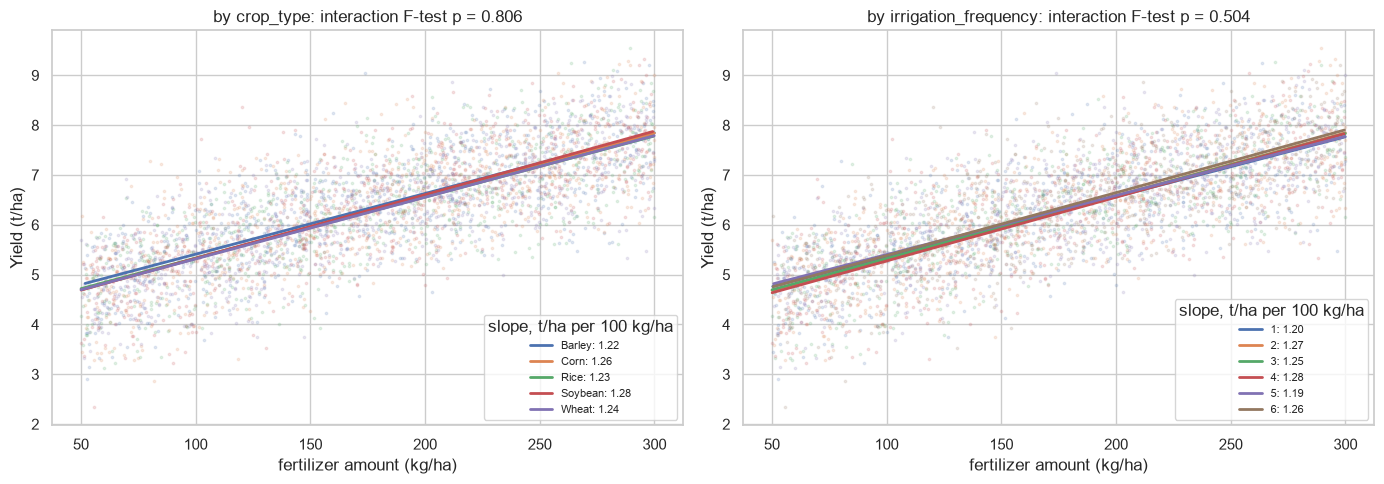

In [15]:
x_col = top_pearson_feature(train)  # the strongest feature (fertilizer_amount)
SLOPE_PER = 100  # report slopes per 100 units of x for readability
fig, axes = plt.subplots(1, len(config.INTERACTION_MODERATORS), figsize=(14, 5))
for ax, moderator in zip(axes, config.INTERACTION_MODERATORS):
    slopes = {}
    for level, d in train.groupby(moderator):
        slope, intercept = np.polyfit(d[x_col], d[config.TARGET], 1)
        slopes[level] = round(float(slope * SLOPE_PER), 3)
        xs = np.linspace(d[x_col].min(), d[x_col].max(), 2)
        ax.scatter(d[x_col], d[config.TARGET], s=3, alpha=0.15)
        ax.plot(xs, intercept + slope * xs, lw=2, label=f"{level}: {slopes[level]:.2f}")
    full = smf.ols(f"{config.TARGET} ~ {x_col} * C({moderator})", data=train).fit()
    reduced = smf.ols(f"{config.TARGET} ~ {x_col} + C({moderator})", data=train).fit()
    p_inter = full.compare_f_test(reduced)[1]
    ax.set(xlabel=axis_label(x_col), ylabel=Y_LABEL, title=f"by {moderator}: interaction F-test p = {p_inter:.3f}")
    ax.legend(title=f"slope, t/ha per {SLOPE_PER} {config.UNITS[x_col]}", fontsize=8)
    print(f"{moderator}: slopes {slopes}, interaction p = {p_inter:.3f}")
save_figure(fig, "eda_interaction_fertilizer")

**Interpretation.** The fertilizer slope is ≈ 1.2–1.3 t/ha per 100 kg/ha for
every crop and every irrigation level — the lines are parallel, and both
interaction F-tests are far from significant (printed above). **There is no
evidence of a fertilizer × crop or fertilizer × irrigation interaction.** So if
tree models beat polynomial models later, it will *not* be because of these
interactions; the likelier explanation would be the threshold/curved shapes in
section 10. A reasonable expectation is that tree models will *not* clearly beat
a polynomial linear model on this data.

## 12. Why `harvest_date` and `field_id` were dropped

harvest month ANOVA p = 0.558; field_id eta^2 = 0.135, random-label mean = 0.130, permutation p = 0.259


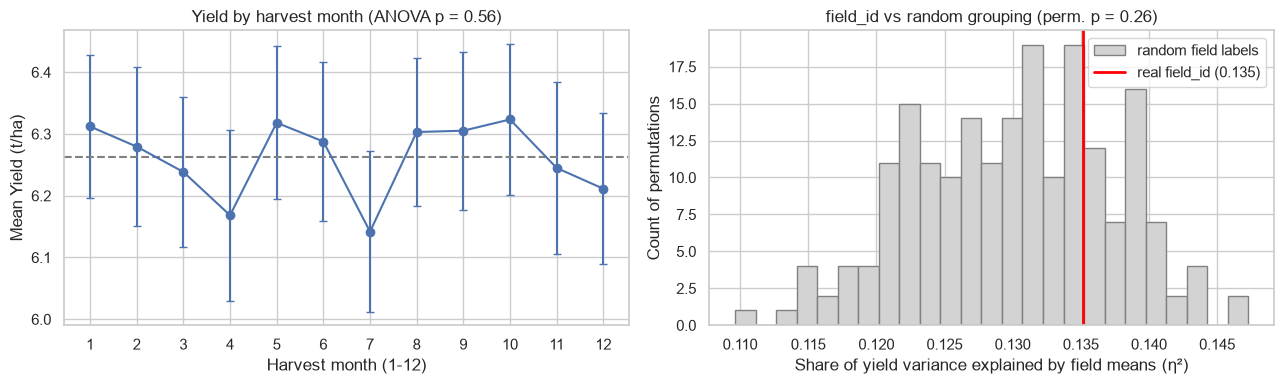

In [16]:
N_PERMUTATIONS = 200
raw = pd.read_csv(config.KAGGLE_TRAIN_CSV).loc[train.index]
# Guard: the re-attached raw rows must be the same rows as the training split.
pd.testing.assert_frame_equal(raw[config.FEATURES + [config.TARGET]], train[config.FEATURES + [config.TARGET]], check_dtype=False)

month = pd.to_datetime(raw[config.HARVEST_DATE_COLUMN]).dt.month
month_p = smf.ols(f"{config.TARGET} ~ C(month)", data=train.assign(month=month)).fit().f_pvalue


def between_group_share(groups: pd.Series) -> float:
    """Share of yield variance explained by group means (eta squared)."""
    return float(y.groupby(groups).transform("mean").var() / y.var())


field = raw[config.FIELD_ID_COLUMN]
eta_field = between_group_share(field)
rng = np.random.default_rng(config.RANDOM_STATE)
null_eta = [between_group_share(pd.Series(rng.permutation(field.to_numpy()), index=field.index)) for _ in range(N_PERMUTATIONS)]
perm_p = (np.sum(np.array(null_eta) >= eta_field) + 1) / (N_PERMUTATIONS + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
by_month = y.groupby(month).agg(["mean", "std", "size"])  # one point per calendar month
half_width = 1.96 * by_month["std"] / np.sqrt(by_month["size"])
axes[0].errorbar(by_month.index, by_month["mean"], yerr=half_width, fmt="o-", capsize=3)
axes[0].axhline(y.mean(), color="grey", ls="--")
axes[0].set(xlabel="Harvest month (1-12)", xticks=range(1, 13), ylabel="Mean " + Y_LABEL, title=f"Yield by harvest month (ANOVA p = {month_p:.2f})")
axes[1].hist(null_eta, bins=25, color="lightgrey", edgecolor="grey", label="random field labels")
axes[1].axvline(eta_field, color="red", lw=2, label=f"real field_id ({eta_field:.3f})")
axes[1].set(xlabel="Share of yield variance explained by field means (η²)", ylabel="Count of permutations", title=f"field_id vs random grouping (perm. p = {perm_p:.2f})")
axes[1].legend()
save_figure(fig, "eda_dropped_columns")
print(f"harvest month ANOVA p = {month_p:.3f}; field_id eta^2 = {eta_field:.3f}, "
      f"random-label mean = {np.mean(null_eta):.3f}, permutation p = {perm_p:.3f}")

**Interpretation.** Mean yield is flat across harvest months (ANOVA p printed
above is well above 0.05). For `field_id`, field means appear to explain some
variance, but **randomly re-labelling the fields explains just as much**:
with ~500 small groups, group means soak up variance by chance alone. The real
field_id is indistinguishable from random labels (permutation p above). Both
columns carry no signal, and keeping `field_id` would only let a model memorise
IDs that recur in the competition test file. **Dropping both is justified.**

## Summary

| Question | Finding |
|---|---|
| Log-transform target? | **No** — skewness ≈ −0.10 (rule: > 1); log1p worsens it to ≈ −0.52 |
| Top 5 by \|Pearson r\| | fertilizer_amount, pesticide_usage, total_rainfall, soil_moisture, nitrogen_content |
| Top 5 by \|Spearman ρ\| | fertilizer_amount, pesticide_usage, total_rainfall, soil_moisture, nitrogen_content |
| Non-linearity | soil_ph (optimum), phosphorus_content (U), total_rainfall (saturating), fertilizer_amount (diminishing returns) |
| Interactions | none detected for fertilizer × crop or × irrigation |
| Multicollinearity | none (max feature–feature \|r\| < 0.03) |
| Synthetic evidence | uniform features, independent features, no crop/region/season effect, zero outliers |